In [ ]:
import sys
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Force reload calibration_utils to pick up the new manual calibration approach
if 'src.calibration_utils' in sys.modules:
    del sys.modules['src.calibration_utils']
if 'calibration_utils' in sys.modules:
    del sys.modules['calibration_utils']

sys.path.insert(0, './src')
from src.calibration_utils import calibrate_all_models, plot_all_calibration_comparison

In [ ]:
# =============================================================================
# CELLULE 1 :  IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Calibration: {X_cal.shape[0]} lignes, {X_cal.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes, {X_test.shape[1]} features")

📂 Chargement des données...
✓ Données chargées:
   - Calibration: 28381 lignes, 81 features
   - Test: 28465 lignes, 81 features


In [14]:
# =============================================================================
# CELLULE 2 : CALIBRATION DE TOUS LES MODÈLES
# =============================================================================


# Calibrer tous les modèles avec Platt Scaling
results_df = calibrate_all_models(
    model_dir='models',
    output_dir='model_calibrated',
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    method='sigmoid',  # Platt Scaling
    pattern='*_tuned.pkl',
    save_plots=True,
    plot_dir='model_calibrated/plots'
)

print("\n✅ Calibration terminée!")

📂 Modèles trouvés dans 'models':
   - xgboost_tuned.pkl
   - logistic_regression_tuned.pkl
   - random_forest_tuned.pkl

🔄 CALIBRATION DE 3 MODÈLES
   Méthode: sigmoid (Platt Scaling)
   Données calibration: 28381 échantillons
   Données test: 28465 échantillons

──────────────────────────────────────────────────
📦 Modèle: xgboost
──────────────────────────────────────────────────
   ✓ Modèle chargé: models/xgboost_tuned.pkl
   🔄 Calibration avec méthode: sigmoid

   📊 Métriques sur Test Set:
      Brier Score:   0.2106 → 0.2664 (↑ 0.0558)
      Log Loss:      0.6339 → 0.9670 (↑ 0.3331)
      ROC-AUC:       0.7533 → 0.7289
   ✓ Plot sauvegardé:  results/xgboost_calibrated/xgboost_calibration_curve.png
   ✓ Métriques sauvegardées: results/xgboost_calibrated/xgboost_calibrated_metrics.csv
   ✓ Résultats sauvegardés: results/xgboost_calibrated/xgboost_calibrated_results.txt
   ✓ Modèle calibré sauvegardé: model_calibrated/xgboost_tuned_calibrated.pkl

─────────────────────────────────────

/home/mouad-sehli/datascience/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/mouad-sehli/datascience/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



   📊 Métriques sur Test Set:
      Brier Score:   0.1927 → 0.2040 (↑ 0.0114)
      Log Loss:      0.5675 → 0.5979 (↑ 0.0304)
      ROC-AUC:       0.7768 → 0.7541
   ✓ Plot sauvegardé:  results/logistic_regression_calibrated/logistic_regression_calibration_curve.png
   ✓ Métriques sauvegardées: results/logistic_regression_calibrated/logistic_regression_calibrated_metrics.csv
   ✓ Résultats sauvegardés: results/logistic_regression_calibrated/logistic_regression_calibrated_results.txt
   ✓ Modèle calibré sauvegardé: model_calibrated/logistic_regression_tuned_calibrated.pkl

──────────────────────────────────────────────────
📦 Modèle: random_forest
──────────────────────────────────────────────────
   ✓ Modèle chargé: models/random_forest_tuned.pkl
   🔄 Calibration avec méthode: sigmoid

   📊 Métriques sur Test Set:
      Brier Score:   0.1915 → 0.2217 (↑ 0.0301)
      Log Loss:      0.5648 → 0.6705 (↑ 0.1057)
      ROC-AUC:       0.7790 → 0.7502
   ✓ Plot sauvegardé:  results/random_fore

✓ Comparaison sauvegardée:  model_calibrated/comparison_calibration.png


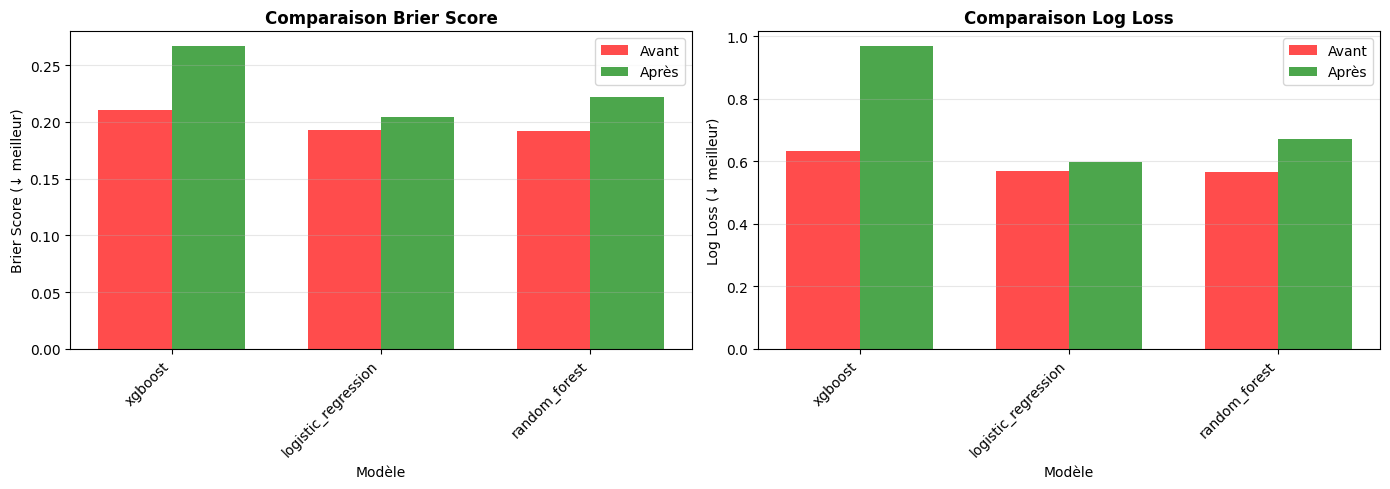


📊 Tableau récapitulatif:
              model  brier_before  brier_after  log_loss_before  log_loss_after  roc_auc_before  roc_auc_after  brier_improvement  log_loss_improvement
            xgboost      0.210556     0.266357         0.633890        0.967002        0.753270       0.728926          -0.055801             -0.333111
logistic_regression      0.192674     0.204037         0.567533        0.597888        0.776755       0.754051          -0.011362             -0.030355
      random_forest      0.191530     0.221679         0.564798        0.670468        0.779009       0.750189          -0.030149             -0.105670


In [15]:
# =============================================================================
# CELLULE 3 : VISUALISATION COMPARATIVE
# =============================================================================
from src.calibration_utils import plot_all_calibration_comparison

# Plot comparaison de tous les modèles
fig = plot_all_calibration_comparison(
    results_df, 
    save_path='model_calibrated/comparison_calibration.png'
)
plt.show()

# Afficher le tableau récapitulatif
print("\n📊 Tableau récapitulatif:")
print(results_df.to_string(index=False))